**You may use code to solve these problems. You may then sketch what your plots show, or add the plots to this homework and submit a pdf digitally (email).**

**Problem 1.** Suppose the data are `[1, 1.75, 2, 3, 3.25, 4]`.

- a. Sketch the empirical cumulative distribution function.
- b. Sketch the uniform kernel density estimator for a bandwidth of `h = 0.2`
- c. Compute the Silverman bandwidth for the uniform kernel using `h = 1.84 * SD * n**(-0.2)`.
- d. Sketch the uniform kernel density estimator for the Silverman bandwidth.
- e. How are b and d similar or different?

# Problems: Kernel Density Estimation

# Question A.
![alt text](brah'.PNG)

# Question B.
![alt text](brah.png)

$$
X=[1,1.75,2,3,3.25,4]
$$

$$
h=0.2,\qquad n=6
$$

$$
\frac{1}{n(2h)}
=
\frac{1}{6(2)(0.2)}
=
\frac{1}{2.4}
\approx 0.4167
$$

$$
[0.8,1.2],\quad
[1.55,1.95],\quad
[1.8,2.2],\quad
[2.8,3.2],\quad
[3.05,3.45],\quad
[3.8,4.2]
$$



# Question C.

In [11]:
import numpy as np
data=[1, 1.75, 2, 3, 3.25, 4]
h = 1.84 * np.std(data) * 6**(-0.2)
print(f" The computed Silverman's bandwidth is: {h}")

 The computed Silverman's bandwidth is: 1.2991670409500977


# Question D.
$$
X=[1,1.75,2,3,3.25,4]
$$

$$
h=1.3,\qquad n=6
$$
$$
\frac{1}{n(2h)}
=
\frac{1}{6(2)(1.3)}
=
\frac{1}{15.6}
\approx 0.0641025
$$


In [14]:
# Determining Intervals From Silverman's Bandwidth
for i in data:
    lower_bound=i-h
    upper_bound=i+h

    print(lower_bound,upper_bound,i)

-0.2991670409500977 2.2991670409500977 1
0.4508329590499023 3.0491670409500977 1.75
0.7008329590499023 3.2991670409500977 2
1.7008329590499023 4.299167040950097 3
1.9508329590499023 4.549167040950097 3.25
2.7008329590499023 5.299167040950097 4


![alt text](Untitled.png)

# Question E.

B and D are different because the bandwidth is drastically changing the interval for each kernel. What was once .2 is now 1.3, which makes it so densities are stretched out over a wide area. Since the Uniform KDE is being streched in D, the KDE is far less sensitive to specific values. For example in B, the upper and lower bounds were small but accounted for a large portion of the density. In D, this is not the case.

**Problem 2.** Suppose the data `X = [-1, -0.5, 0, 0.5, 1]` were drawn from a standard Normal distribution.

- a. Using the uniform kernel with `h = 0.6`, compute the realized KDE at `x = 0`, `f_hat_h(0)`, directly from these five numbers.
- b. Now compute `E[f_hat_h(0)]` at the same `h = 0.6`.
- c. Calculate the true density at `x=0`, using the Normal distribution.
- d. Are b and c equal? What does this mean about bias? (Keep in mind, truly proving anything about bias would require us to compare `E[f_hat_h]` to the Normal distribution for all x; calculating this at one point is only an indication of what is going on that you can extrapolate from.)
- e. Recompute `E[f_hat_h(0)]` from (b) at a much smaller bandwidth, `h = 0.1`. What happens to the gap between `E[f_hat_h(0)]` and `f(0)` as `h` shrinks?
- f. Is `f_hat_h` a consistent estimator? Explain your reasoning.
- g. What are the main considerations in choosing a bandwidth value `h`?

# Question 2.A

In [ ]:
#a.
data=[-1, -0.5, 0, 0.5, 1]
h=.6
for i in data:
    lower_bound=i-h
    upper_bound=i+h

    print(lower_bound,upper_bound,)


-1.6 -0.4 -1
-1.1 0.09999999999999998 -0.5
-0.6 0.6 0
-0.09999999999999998 1.1 0.5
0.4 1.6 1


because three of the values have zero in its bounds `[-.5,0,.5]`

$$
\hat{f}_h(0) = \left(\frac{1}{(5)(0.6)}\right)\left(\frac{3}{2}\right) = 0.5
$$

# Question 2.B

$$
E[\hat f_h(x)] = \frac{F(x+h) - F(x-h)}{2h}
$$

In [20]:
#Typing this into Code:
from scipy.stats import norm

expected_kde = (norm.cdf(h) - norm.cdf(-h)) / (2 * h)

print(expected_kde)

0.3762448037498774


# Question 2.C

In [ ]:
# Code Again
true_density = norm.pdf(0)

print(true_density)

0.3989422804014327


In [23]:
difference=expected_kde-true_density

difference

np.float64(-0.022697476651555304)

# Question 2.D

C and D are not equal. The expected KDE at x=0 is .0227 lower than the true density. This is because our $h$, which equals .6 is not zero. However this is only for one point in the distribution. Like the wording of the question suggests, if we wanted to make a statment of bias we would have to calculate the expected KDE for the entire distribution.

# Question 2.E

In [ ]:
#Computing KDE With Updated Bandwidth
h=.1
expected_kde = (norm.cdf(h) - norm.cdf(-h)) / (2 * h)

difference=expected_kde-true_density

print(expected_kde,difference)

0.3982783727702899 -0.0006639076311428238


The difference between the expected KDE and the true density shrinks massively as $h$ decreases from .6 to .1. As $h$ approaches zero, the expected KDE gets closer to the true density.

# Question 2.F

No, `f_hat_h` is not a constient estimator in this case because we have a **fixed bandwidth**. With silverman's bandwidth, $h$ approaches zero as n grows larger so in that case we would conclude that the KDE is consistent, but since we have a fixed bandwidth (.6,.1) the estimate does not converge on to the true density as the sample $n$ increases. 

# Question 2.G

We must choose between a bias variance tradeoff when choosing our bandwidth. At smaller bandwidth values, the bias is low but the variance is high since we are following each value of X closely. At higher bandwidth value, the bias is high but the variance is low since we are smoothing our KDE heavily.

That is why silverman's banndwidth is a good and convient starting point for selecting a bandwidth.


**Problem 3.** Suppose the data are `X = [5, 7, 7, 8, 10]`, and fix the bandwidth at `h = 1.5` for both kernels below.

- a. Compute the uniform-kernel KDE, `f_hat_h(x)`, at `x = 6.0`, `x = 6.5`, `x = 7.0`, `x = 8.0`, and `x = 8.5`.
- b. Compute the Gaussian-kernel KDE at the same five values of `x`, using the same `h = 1.5`.
- c. Your part (a) values should jump abruptly between some of these five points, while your part (b) values should change smoothly. Identify where the biggest jump in (a) happens, and explain in terms of the two kernel *shapes* -- not just "one is smoother" -- why that jump exists in the uniform case but not the Gaussian case.
- d. Why might you prefer one kernel over the other in practice?

# Question 3.A

In [31]:
X = [5, 7, 7, 8, 10]
h = 1.5

x_values = [6.0, 6.5, 7.0, 8.0, 8.5]

for x in x_values:
    count = sum(abs(x - xi) <= h for xi in X)
    kde = count / (len(X) * 2 * h)
    print(x, kde)

6.0 0.2
6.5 0.26666666666666666
7.0 0.2
8.0 0.2
8.5 0.26666666666666666


# Question 3.B



In [32]:
X = np.array([5, 7, 7, 8, 10])
h = 1.5

x_values = [6.0, 6.5, 7.0, 8.0, 8.5]

for x in x_values:
    kde = np.sum(
        (1 / np.sqrt(2 * np.pi)) *
        np.exp(-0.5 * ((x - X) / h)**2)
    ) / (len(X) * h)

    print(x, kde)

6.0 0.15116667696891303
6.5 0.16865730580239766
7.0 0.17804448100191994
8.0 0.16744524435137584
8.5 0.15060230537921768


# Question 3.C

The biggest jump occurs at values between values 6.0 - 6.5 and 8.0- 8.5 in the uniform KDE. When we intepret the two realized KDE's as it pertains to their kernel's shape it makes sense. The uniform KDE has strict cutoffs outside of the bandwidth, so a value contributes nothing to the density outside of its bandwidth. In the gaussian kernel each value contributes something, albiet marginally to the density, which is why it recieves a smoother shape bereft of jumps and cutoffs.

# Question 3.D

You might prefer one kernel over the other depending on what exactly you are plotting. If you want a stucture of a KDE where values are strict between certain intervals of x, the uniform kernel might be a better option. If you want a stucture where sensitivity to certain values of x is marginal outside of its bandwidth, the gaussian might be the preferred option. It depends on what you are modeling.

**Problem 4.** Load `./data/heart_failure_clinical_records_dataset.csv`.

- a. Plot a
- kernel density estimate of `ejection_fraction`.
- b. Use Pandas' `df.sample(frac=1.0, replace=True)` to resample the data 15 times with replacement, plotting the kernel density estimtes for each sample.
- c. For what values of `ejection_fraction` is the original plot reliable? For which values is there noticeable variation in your plots of the resampled data?

In [45]:
# Set Up
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
df=pd.read_csv('./data/heart_failure_clinical_records_dataset.csv')
df

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
294,62.0,0,61,1,38,1,155000.00,1.1,143,1,1,270,0
295,55.0,0,1820,0,38,0,270000.00,1.2,139,0,0,271,0
296,45.0,0,2060,1,60,0,742000.00,0.8,138,0,0,278,0
297,45.0,0,2413,0,38,0,140000.00,1.4,140,1,1,280,0


# Question 4.A

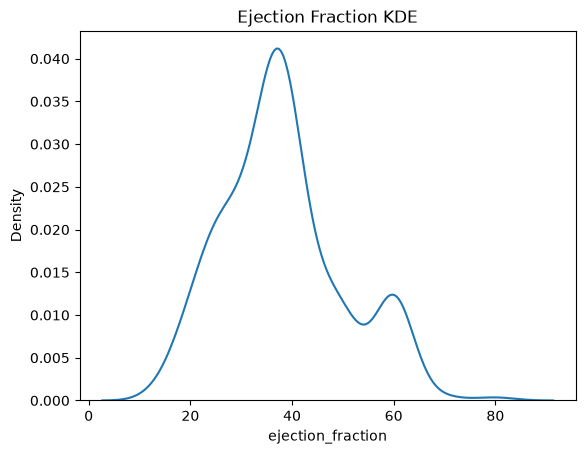

In [46]:
sns.kdeplot(df['ejection_fraction'])

plt.title('Ejection Fraction KDE')
plt.xlabel('ejection_fraction')
plt.ylabel('Density')
plt.show()

# Question 4.B

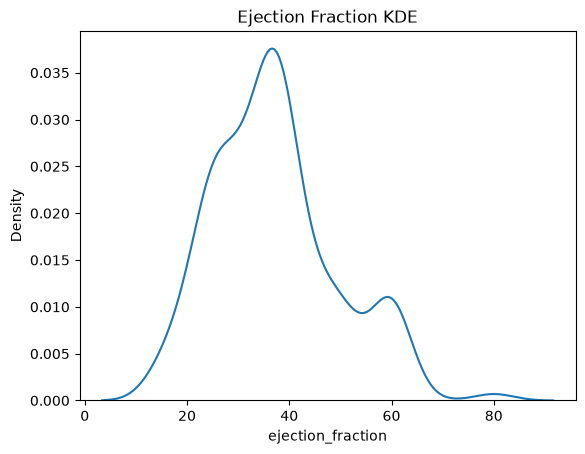

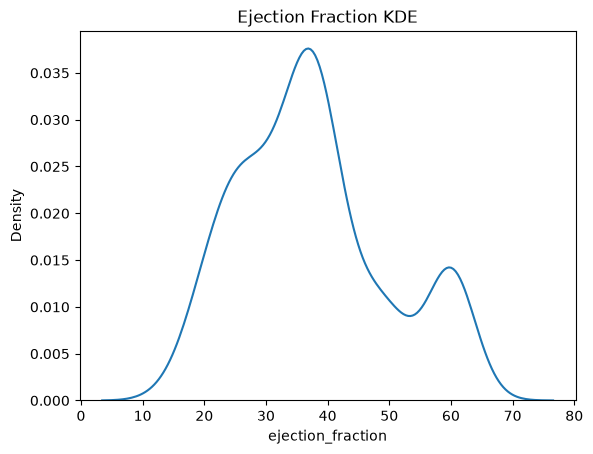

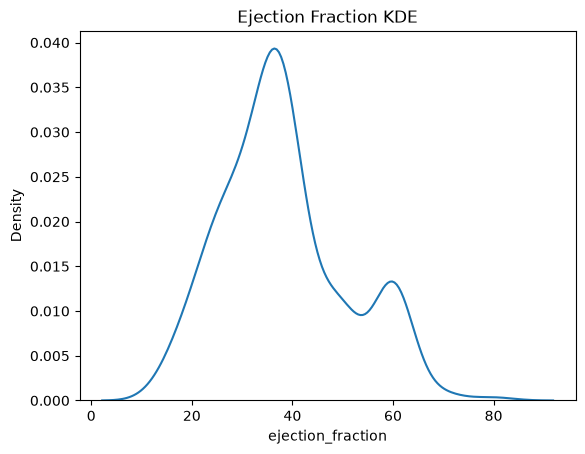

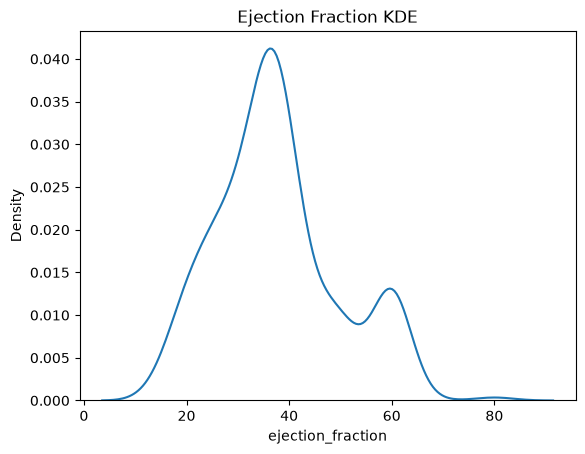

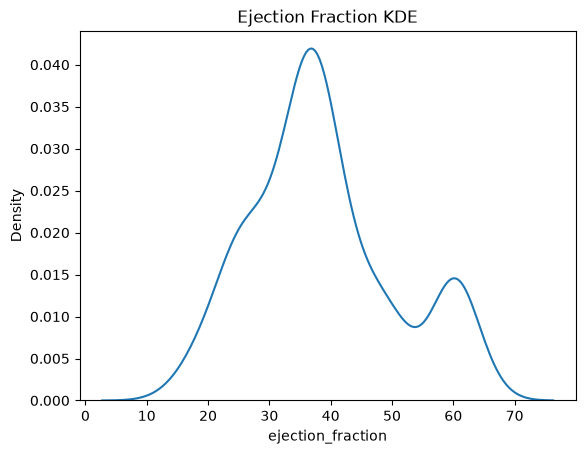

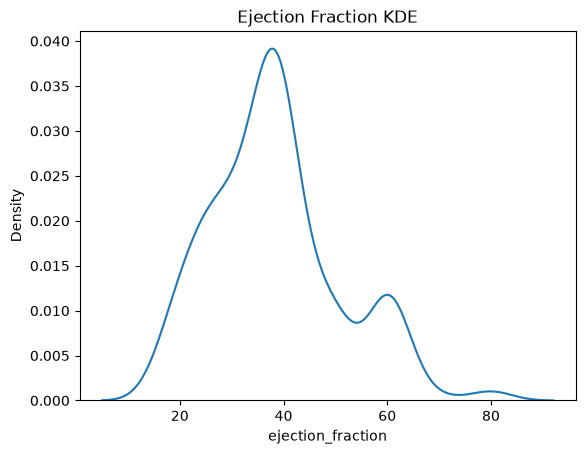

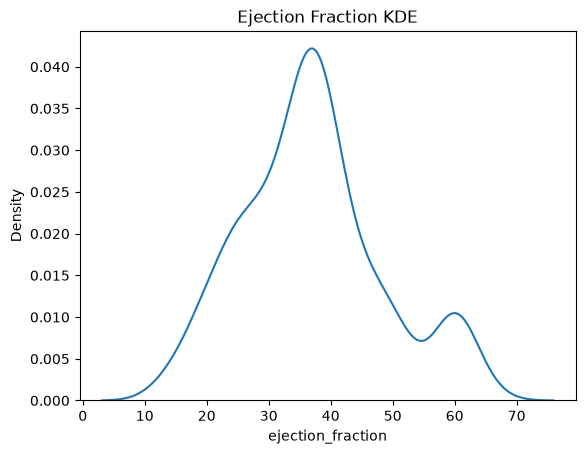

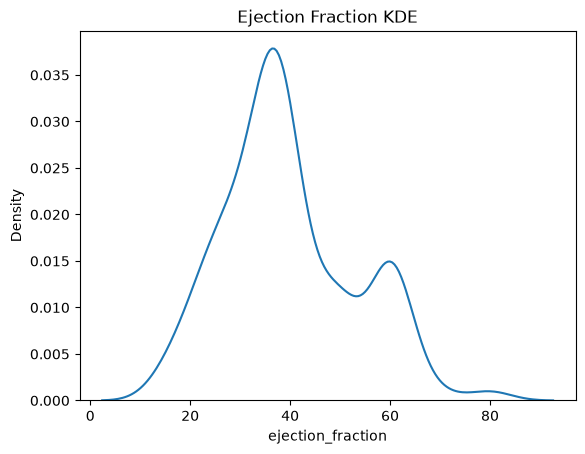

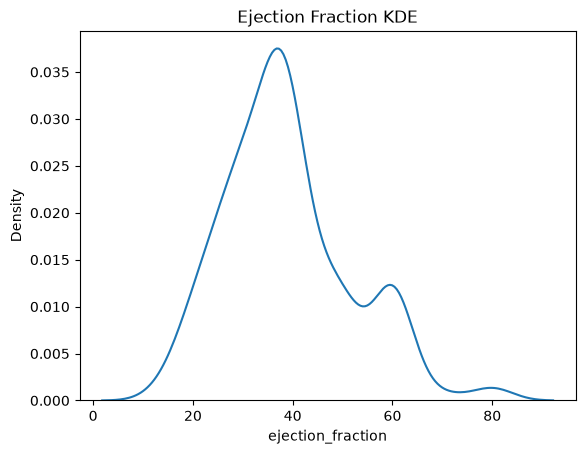

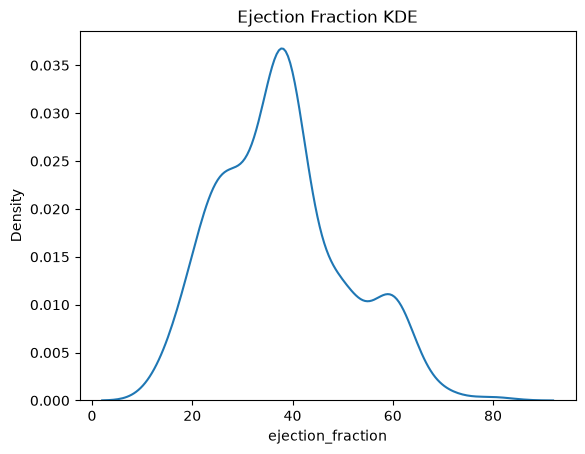

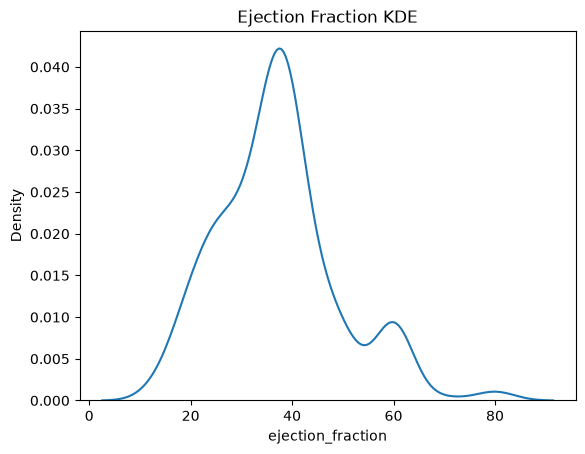

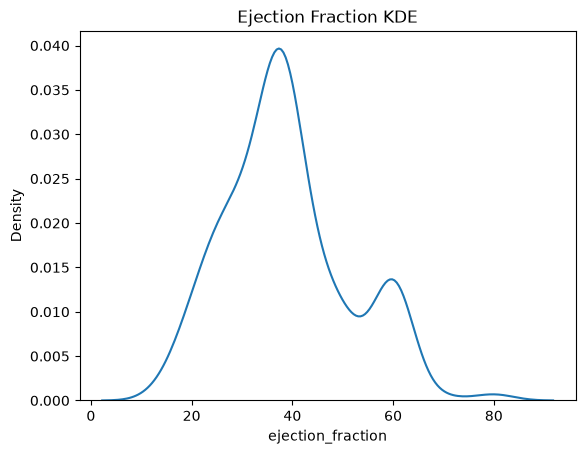

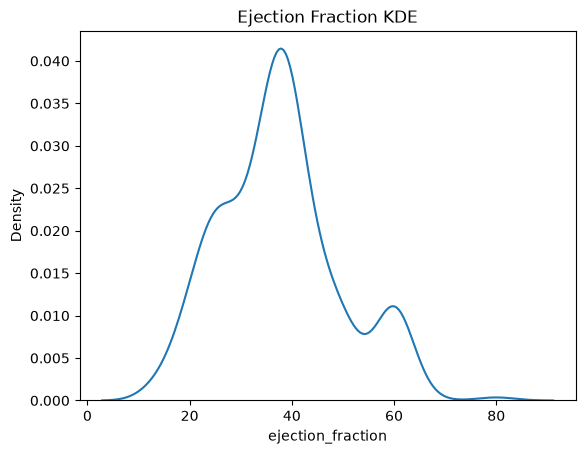

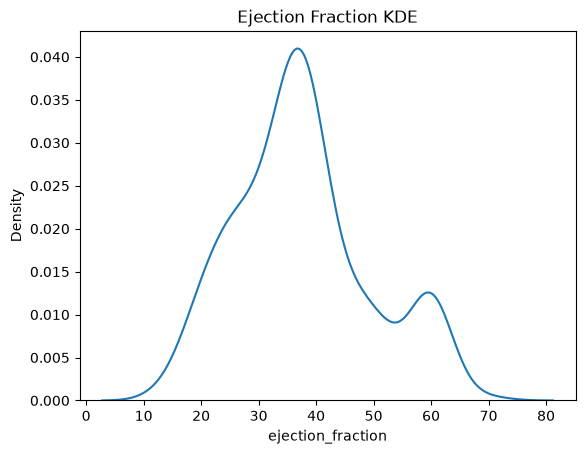

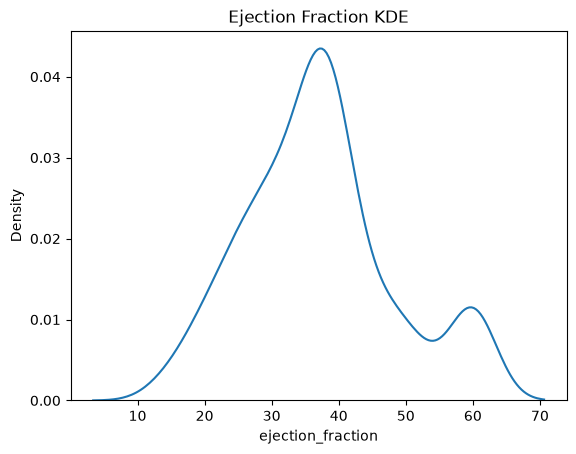

In [50]:
for i in range(15):
    df_new=df.sample(frac=1.0, replace=True)
    sns.kdeplot(df_new['ejection_fraction'])

    plt.title('Ejection Fraction KDE')
    plt.xlabel('ejection_fraction')
    plt.ylabel('Density')
    plt.show()

# Question 4.C

After looking at the 15 plot from my boostrap resampling of the data, I believe the only reliable values are ones with no considerable concentration in terms of value density, like 10 or 20. All the other values, especially those with higher concentrations like 30 or 60, have some degree of variation amongst the boostrap resampling plots.